# Качество данных лабораторной работы 5

**ПМИ-2-2025. Вариант 3.**

Основной набор — все 100 уникальных цитат `quotes.toscrape.com` с данными авторов. Дополнительно выполнен расширенный обход тегов по подходу из репозитория LaintAge/web-scrapers. Отдельная таблица `quote_tags` хранит связи цитат с тегами. Она не увеличивает число уникальных цитат; общий минимум 300 уникальных цитат недостижим на данном каталоге. Дубли и повторные появления под разными тегами не считаются новыми цитатами.

Ноутбук читает сохранённую SQLite, выполняет проверки и пересоздаёт `current.json`, `completeness.csv` и графики. Сетевые запросы не выполняются.

In [1]:
from pathlib import Path
import sys, json, sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

LAB = Path.cwd() if (Path.cwd() / "scrapy.cfg").exists() else Path.cwd().parent
sys.path.insert(0, str(LAB / "quality"))
from analyze import read_rows, summarize, write_report
from smoke_check import check
summary = write_report(LAB / "data/crawl.db", LAB / "quality")
quotes = pd.DataFrame(read_rows(LAB / "data/crawl.db"))
relations = pd.DataFrame(read_rows(LAB / "data/crawl.db", "quote_tags"))
q = summary
display(pd.DataFrame([{"table": "quotes", "rows": len(quotes), "meaning": "уникальные цитаты"}, {"table": "quote_tags", "rows": len(relations), "meaning": "связи цитата-тег"}]))
assert len(quotes) == 100 and len(q["list_pages"]) >= 10
assert q["unique_keys"] == 100 and q["invalid_business_keys"] == 0
assert q["tag_associations"] == q["unique_tag_associations"] > 0
assert q["orphan_tag_associations"] == 0
print("Связей:", q["tag_associations"], "; обнаружено тегов:", q["tags_discovered"])

,table,rows,meaning
0,quotes,100,уникальные цитаты
1,quote_tags,190,связи цитата-тег


Связей: 190 ; обнаружено тегов: 99


## Полнота каждого поля и типы

Полнота равна числу непустых значений, делённому на число строк. Для `tags_json` считается наличие хотя бы одного тега: пустой массив допустим на сайте и отдельно отмечается как отсутствие классификации. Доля пустых обязательных полей для smoke-check — число пустых обязательных ячеек, делённое на общее число обязательных ячеек. Пустой массив тегов допустим; номер страницы должен быть положительным целым числом.

In [2]:
completeness = pd.read_csv(LAB / "quality/completeness.csv")
display(completeness)
assert summary["required_empty_share"] == 0
assert q["duplicates"] == 0
assert quotes["born_date"].map(lambda x: bool(pd.to_datetime(x, format="%Y-%m-%d"))).all()
print("Авторы:", q["authors_count"], "; цитаты без тегов:", q["completeness"]["tags_json"]["empty"])
print("Полнота рассчитана после DropItem; потери при сборе отдельно отражены в dropped/*.")

,field,filled,empty,percent
0,business_key,100,0,100.0
1,quote,100,0,100.0
2,author,100,0,100.0
3,tags_json,97,3,97.0
4,author_url,100,0,100.0
5,born_date,100,0,100.0
6,born_location,100,0,100.0
7,biography,100,0,100.0
8,source_url,100,0,100.0
9,list_page,100,0,100.0


Авторы: 50 ; цитаты без тегов: 3
Полнота рассчитана после DropItem; потери при сборе отдельно отражены в dropped/*.


## Статистика сохранённых прогонов

Счётчики HTTP и байтов Scrapy отражают работу downloader middleware, включая ответы из кэша. Для прогонов с кэшем число новых сетевых запросов вычисляется как `downloader/request_count - httpcache/hit`; для используемого DummyPolicy нет ревалидации. Значения трафика Scrapy включают HTTP-заголовки и сжатое тело. Начальный отладочный прогон, если сохранён, указан отдельно и не используется как итоговый набор.

In [3]:
runs = pd.DataFrame(summary["runs"])
display(runs[["file", "items", "db_written", "relations_written", "elapsed_seconds", "network_requests", "httpcache_hit", "httpcache_store", "finish_reason"]])
display(runs[["file", "relations_attempted", "relations_written", "relations_ignored", "responses", "retries", "request_bytes", "response_bytes", "dropped"]])

,file,items,db_written,relations_written,elapsed_seconds,network_requests,httpcache_hit,httpcache_store,finish_reason
0,stats_benchmark30.json,30,30,0,9.480815,24,0,0,finished
1,stats_cache_cold.json,100,100,0,27.588688,61,0,61,finished
2,stats_cache_warm.json,100,100,0,3.036871,0,61,0,finished
3,stats_job_pause.json,34,34,0,0.593403,0,23,0,closespider_itemcount
4,stats_job_resume.json,66,66,0,0.804952,0,39,0,finished
5,stats_tags.json,190,0,190,70.164591,161,0,0,finished


,file,relations_attempted,relations_written,relations_ignored,responses,retries,request_bytes,response_bytes,dropped
0,stats_benchmark30.json,0,0,0,"{'404': 1, '200': 23}",0,7465,40326,{}
1,stats_cache_cold.json,0,0,0,"{'404': 1, '200': 60}",0,19246,105763,{}
2,stats_cache_warm.json,0,0,0,"{'404': 1, '200': 60}",0,19246,105763,{}
3,stats_job_pause.json,0,0,0,"{'404': 1, '200': 22}",0,7126,38127,{}
4,stats_job_resume.json,0,0,0,"{'404': 1, '200': 38}",0,12383,67979,{}
5,stats_tags.json,190,190,0,"{'404': 1, '200': 160}",0,52614,227068,{'dropped/duplicate_relation': 73}


## Аналитические агрегаты

Распределение цитат по авторам, тегам и векам рождения авторов описывает именно учебный каталог. Один текст может иметь несколько тегов, поэтому их частоты не суммируются в число цитат. Частоты тегов из основного каталога и связи, реально обнаруженные обходом страниц тегов, сравниваются отдельно: расширенный обход может охватить не все изолированные теги.

,quotes
Albert Einstein,10
J.K. Rowling,9
Marilyn Monroe,7
Dr. Seuss,6
Mark Twain,6
Jane Austen,5
C.S. Lewis,5
Bob Marley,3
Suzanne Collins,2
Eleanor Roosevelt,2


,quotes
love,14
inspirational,13
life,13
humor,12
books,11
reading,7
friendship,5
friends,4
truth,4
simile,3


,quotes
18,5
19,41
20,54


,associations
source_tag,
love,14
life,13
inspirational,13
humor,12
books,11
reading,7
friendship,5
friends,4
truth,4


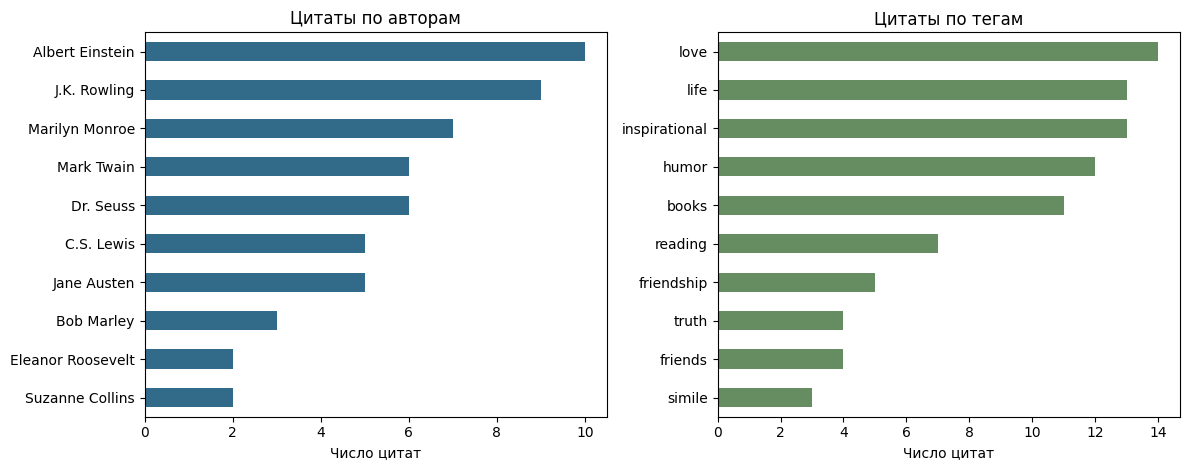

In [4]:
authors = pd.Series(q["quotes_by_author"], name="quotes").sort_values(ascending=False)
tags = pd.Series(q["quotes_by_tag"], name="quotes").sort_values(ascending=False)
centuries = pd.Series(q["quotes_by_author_birth_century"], name="quotes")
display(authors.head(10).to_frame())
display(tags.head(10).to_frame())
display(centuries.to_frame())
display(relations.groupby("source_tag").size().sort_values(ascending=False).head(10).to_frame("associations"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
authors.head(10).sort_values().plot.barh(ax=axes[0], color="#326b8a", title="Цитаты по авторам")
tags.head(10).sort_values().plot.barh(ax=axes[1], color="#668c62", title="Цитаты по тегам")
for ax in axes: ax.set_xlabel("Число цитат"); ax.set_ylabel("")
fig.tight_layout()
(LAB / "quality/figures").mkdir(exist_ok=True)
fig.savefig(LAB / "quality/figures/quotes_aggregates.png", dpi=160, bbox_inches="tight")
plt.show()

## Раннее обнаружение поломки

Сравниваются два независимых прогона одного окна цитат: холодный кэш и итоговый сбор. Сравнение с накопленной БД вместо текущего прогона могло бы скрыть потерю данных, поэтому исходный снимок вычисляется из отдельной базы эксперимента. Пороги строгие: падение **более** 20% или пустота обязательных ячеек **более** 5%. Синтетические проверки границ вынесены в `check_smoke.py` и не выдаются за реальные прогоны.

In [5]:
previous = summarize(read_rows(LAB / "data/cache_cold.db"))
current = summarize(read_rows(LAB / "data/crawl.db"))
for name, value in [("previous.json", previous), ("quotes_snapshot.json", current)]:
    (LAB / "quality" / name).write_text(json.dumps(value, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
warnings = check(previous, current)
print("Предыдущий прогон:", previous["rows"], "; текущий:", current["rows"])
print(warnings or "Smoke-check: OK")
assert not warnings
from check_smoke import main as check_boundaries
check_boundaries()

Предыдущий прогон: 100 ; текущий: 100
Smoke-check: OK
Smoke thresholds and invalid inputs: 11 checks passed


## Сопоставление с n8n

Сравнение проводится по первым трём страницам, по 30 уникальных цитат с одинаковыми полями. Временные метки сбора и технические URL перенаправлений могут отличаться. Содержание полей сравнивается после одинакового схлопывания пробелов. Итоговая таблица времени, запросов и трафика находится в отчёте и файлах статистики.

In [6]:
nocode = pd.read_csv(LAB / "nocode/nocode_result.csv", keep_default_na=False)
required_columns = {"quote", "author", "tags", "author_url", "born_date", "born_location", "biography", "source_url", "list_page", "collected_at", "business_key"}
assert required_columns <= set(nocode.columns), required_columns - set(nocode.columns)
assert len(nocode) == 30
for field in required_columns - {"tags", "list_page"}:
    assert nocode[field].map(lambda value: bool(str(value).strip())).all(), field
assert nocode["born_date"].str.fullmatch(r"\d{4}-\d{2}-\d{2}").all()
pd.to_datetime(nocode["born_date"], format="%Y-%m-%d", errors="raise")
pd.to_datetime(nocode["collected_at"], utc=True, errors="raise")
assert nocode["list_page"].value_counts().to_dict() == {1: 10, 2: 10, 3: 10}
normalize = lambda value: " ".join(str(value).split())
expected = {(normalize(row.author).lower(), normalize(row.quote)): row for row in quotes.itertuples() if row.list_page <= 3}
actual = {(normalize(row.author).lower(), normalize(row.quote)): row for row in nocode.itertuples()}
assert len(actual) == 30 and set(expected) == set(actual)
for key, row in actual.items():
    for field in ["born_date", "born_location", "biography", "business_key"]:
        assert normalize(getattr(row, field)) == normalize(getattr(expected[key], field)), (key[0], field)
    assert sorted(json.loads(row.tags)) == sorted(json.loads(expected[key].tags_json)), key[0]
print("30 уникальных ключей, даты, биографии и теги совпали со Scrapy; все поля схемы присутствуют.")

30 уникальных ключей, даты, биографии и теги совпали со Scrapy; все поля схемы присутствуют.
